# Modul 12 — Optimasi Interval Penggantian Preventif vs Produksi
**Keputusan:** untuk komponen kritis, kapan sebaiknya diganti *sebelum* rusak? Mengganti terlalu dini membuang umur komponen dan membuat berhenti terencana terlalu sering; menunggu rusak membuat berhenti mendadak yang lebih lama dan lebih mahal.

Alat: **kebijakan penggantian berdasarkan umur** (age replacement). Ganti komponen pada umur *T* atau saat rusak, mana yang lebih dulu. Dengan model Weibull dari Modul 4, kita cari *T* yang meminimalkan **jam produksi hilang per hari**, lalu menguji keputusan itu terhadap ketidakpastian parameter dengan Monte Carlo.

Kunci pelajarannya: **penggantian preventif hanya masuk akal jika komponen menua (β > 1)**. Pada β ≤ 1, mengganti komponen yang masih baik tidak mengurangi peluang rusak.

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import optimize

pd.set_option("display.width", 140, "display.max_columns", 30)
XLSX = "Smelter_Data_Lanjutan.xlsx"
try:
    from google.colab import files
    if not os.path.exists(XLSX): files.upload()
except ImportError:
    pass
S = pd.read_excel(XLSX, sheet_name=None)
komp, log, harian, harga = S["Komponen_Kritis"], S["Downtime_Log"], S["Data_Harian"], S["Harga_Biaya"]
rng = np.random.default_rng(12)
np.seterr(all="ignore")

Saving Smelter_Data_Lanjutan.xlsx to Smelter_Data_Lanjutan.xlsx


{'divide': 'warn', 'over': 'warn', 'under': 'ignore', 'invalid': 'warn'}

## 1. Estimasi Weibull (sama dengan Modul 4: data tersensor dan left-truncated)

In [ ]:
def fit_weibull(masuk, keluar, gagal):
    masuk, keluar, gagal = map(lambda x: np.asarray(x, float), (masuk, keluar, gagal))
    def nll(par):
        b, e = np.exp(par)
        ll = (gagal * (np.log(b) - b*np.log(e) + (b-1)*np.log(keluar))).sum() - (((keluar/e)**b) - ((masuk/e)**b)).sum()
        return -ll if np.isfinite(ll) else 1e12
    r = optimize.minimize(nll, [0.0, np.log(keluar.mean())], method="Nelder-Mead", options={"xatol": 1e-7, "fatol": 1e-9, "maxiter": 3000})
    return tuple(np.exp(r.x))
komp["masuk"] = komp.Umur_Awal_Hari; komp["keluar"] = komp.Umur_Awal_Hari + komp.Durasi_Pengamatan_Hari
JENIS = list(komp.Jenis.unique())
est, boot = {}, {}
for j in JENIS:
    g = komp[komp.Jenis == j].reset_index(drop=True); est[j] = fit_weibull(g.masuk, g.keluar, g.Gagal_1_Sensor_0); bs = []
    for _ in range(300):
        s = g.sample(len(g), replace=True, random_state=int(rng.integers(1e9)))
        if s.Gagal_1_Sensor_0.sum() >= 2:
            b, e = fit_weibull(s.masuk, s.keluar, s.Gagal_1_Sensor_0)
            if 0.2 < b < 8 and 5 < e < 2000: bs.append((b, e))
    boot[j] = np.array(bs)
print(pd.DataFrame(est, index=["shape", "eta_hari"]).T.round(2))

                        shape  eta_hari
Tuyere                   1.27    127.88
Blower SO2               4.22    358.43
Kompresor Udara          2.29    175.00
Waste Heat Boiler Tube   2.49    190.61
Demister                 1.42    414.04
Rectifier                0.68    145.76


## 2. Biaya: jam produksi hilang
- **Gagal mendadak:** durasi rata-rata dari **Downtime_Log asli** untuk penyebab yang sepadan.
- **Penggantian terencana:** diasumsikan **50%** dari durasi gagal mendadak (*angka contoh*: ada persiapan, suku cadang tersedia, tidak ada kerusakan ikutan). Ubah `RASIO_TERENCANA` dengan angka nyata.
- **Nilai satu jam produksi** = ton/jam × harga LME rata-rata (pendapatan kotor).

In [ ]:
RASIO_TERENCANA = 0.5
pemetaan = {"Tuyere": "Gangguan tuyere", "Blower SO2": "Trip blower SO2", "Kompresor Udara": "Trip kompresor udara",
            "Waste Heat Boiler Tube": "Kebocoran waste heat boiler", "Demister": "Gangguan demister", "Rectifier": "Gangguan rectifier"}
dur_gagal = {j: log.loc[log.Penyebab == p, "Durasi_Jam"].mean() for j, p in pemetaan.items()}
dur_rencana = {j: v * RASIO_TERENCANA for j, v in dur_gagal.items()}
ton_jam = harian.Katoda_Cu_t.sum() / harian.Jam_Operasi.sum(); nilai_jam = ton_jam * harga.LME_Cu_USD_per_t.mean()
print(pd.DataFrame({"jam_gagal": dur_gagal, "jam_terencana": dur_rencana}).round(2))
print(f"\nNilai 1 jam produksi ≈ {ton_jam:.2f} t x {harga.LME_Cu_USD_per_t.mean():,.0f} USD/t = {nilai_jam:,.0f} USD")

                        jam_gagal  jam_terencana
Tuyere                       3.14           1.57
Blower SO2                   2.33           1.17
Kompresor Udara              4.86           2.43
Waste Heat Boiler Tube       2.86           1.43
Demister                     3.60           1.80
Rectifier                    2.88           1.44

Nilai 1 jam produksi ≈ 25.12 t x 10,200 USD/t = 256,252 USD


## 3. Laju biaya jangka panjang dan T optimal
Untuk kebijakan penggantian pada umur *T*, laju kerugian per hari (renewal-reward theorem):

`C(T) = [ D_p · R(T) + D_f · (1 − R(T)) ] / ∫₀ᵀ R(t) dt`

dengan R(t) = exp(−(t/η)^β), D_f jam hilang saat gagal, D_p jam hilang saat penggantian terencana. Pembanding: **dibiarkan sampai rusak** (T = ∞): `C_RTF = D_f / MTTF`.

In [ ]:
from math import gamma
def laju(T, b, e, Df, Dp, n=2000):
    t = np.linspace(0, T, n); R = np.exp(-(t / e) ** b); integral = np.trapezoid(R, t) if hasattr(np, "trapezoid") else np.trapz(R, t)
    return (Dp * R[-1] + Df * (1 - R[-1])) / integral

hasil = []; grid = np.linspace(10, 600, 120); kurva = {}
for j in JENIS:
    b, e = est[j]; Df, Dp = dur_gagal[j], dur_rencana[j]
    c = np.array([laju(T, b, e, Df, Dp) for T in grid]); kurva[j] = c
    rtf = Df / (e * gamma(1 + 1 / b)); iopt = c.argmin()
    ada_opt = (b > 1) and iopt < len(grid) - 1 and c[iopt] < rtf
    hasil.append(dict(Jenis=j, shape=b, T_opt_hari=grid[iopt] if ada_opt else np.nan, jam_per_100hari_RTF=rtf * 100,
                      jam_per_100hari_opt=(c[iopt] * 100) if ada_opt else np.nan, B10_hari=e * (-np.log(0.9)) ** (1 / b)))
H = pd.DataFrame(hasil).set_index("Jenis"); H["hemat_%"] = (1 - H.jam_per_100hari_opt / H.jam_per_100hari_RTF) * 100
print(H.round(2))
print("\nT_opt kosong (NaN) = tidak ada interval yang mengalahkan 'biarkan sampai rusak' (β ≤ 1, atau selisih biaya terencana vs gagal terlalu kecil).")

                        shape  T_opt_hari  jam_per_100hari_RTF  jam_per_100hari_opt  B10_hari  hemat_%
Jenis                                                                                                 
Tuyere                   1.27         NaN                 2.65                  NaN     21.71      NaN
Blower SO2               4.22      272.77                 0.72                 0.58    210.17    19.60
Kompresor Udara          2.29      163.70                 3.13                 2.95     65.48     5.96
Waste Heat Boiler Tube   2.49      168.66                 1.69                 1.56     77.09     7.76
Demister                 1.42         NaN                 0.96                  NaN     84.74      NaN
Rectifier                0.68         NaN                 1.51                  NaN      5.28      NaN

T_opt kosong (NaN) = tidak ada interval yang mengalahkan 'biarkan sampai rusak' (β ≤ 1, atau selisih biaya terencana vs gagal terlalu kecil).


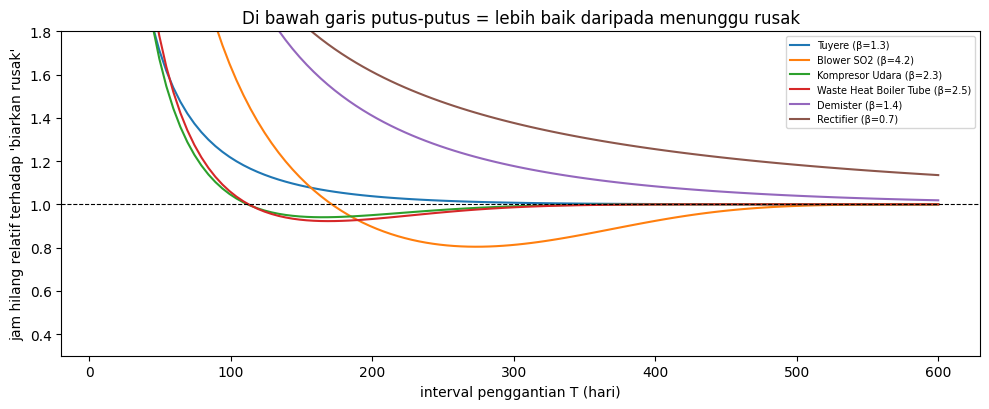

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4.2))
for j in JENIS:
    b, e = est[j]; ax.plot(grid, kurva[j] * 100 / (dur_gagal[j] / (e * gamma(1 + 1 / b)) * 100), label=f"{j} (β={b:.1f})")
ax.axhline(1, color="k", ls="--", lw=.8); ax.set_ylim(0.3, 1.8); ax.set_xlabel("interval penggantian T (hari)"); ax.set_ylabel("jam hilang relatif terhadap 'biarkan rusak'")
ax.set_title("Di bawah garis putus-putus = lebih baik daripada menunggu rusak"); ax.legend(fontsize=7); plt.tight_layout(); plt.show()

## 4. Uji keputusan terhadap ketidakpastian parameter (Monte Carlo)
Parameter Weibull hanya diestimasi dari 6–12 komponen, jadi kebenarannya tidak pasti. Untuk tiap jenis yang punya T_opt, kita:
1. tetapkan kebijakan dari estimasi titik (ganti pada T_opt, atau pada B10 sebagai alternatif),
2. ambil 1.000 "kebenaran yang mungkin" dari bootstrap parameter,
3. simulasikan satu komponen selama 365 hari di bawah tiap kebijakan, hitung jam hilang,
4. laporkan peluang kebijakan itu mengalahkan "biarkan rusak".

In [ ]:
def simulasi_tahun(b, e, T, Df, Dp, hari=365):
    t = 0.0; jam = 0.0
    while t < hari:
        umur = e * rng.weibull(b)
        if umur < T: t += umur; jam += Df
        else: t += T; jam += Dp
        if t > 5 * hari: break
    return jam
rows = []
for j in JENIS:
    if np.isnan(H.loc[j, "T_opt_hari"]): continue
    Df, Dp = dur_gagal[j], dur_rencana[j]; kebijakan = {"RTF": np.inf, "T_opt": H.loc[j, "T_opt_hari"], "B10": H.loc[j, "B10_hari"]}
    draws = boot[j][rng.integers(0, len(boot[j]), 1000)]
    jam = {k: np.array([np.mean([simulasi_tahun(b, e, T, Df, Dp) for _ in range(5)]) for b, e in draws]) for k, T in kebijakan.items()}
    for k in ["T_opt", "B10"]:
        dif = jam["RTF"] - jam[k]
        rows.append(dict(Jenis=j, kebijakan=k, T_hari=kebijakan[k], jam_hemat_per_komponen_tahun=dif.mean(), P5=np.percentile(dif, 5), P95=np.percentile(dif, 95), peluang_lebih_baik_pct=(dif > 0).mean() * 100,
                         USD_hemat_ribu=dif.mean() * nilai_jam / 1e3))
R_ = pd.DataFrame(rows)
print(R_.round(1).to_string(index=False) if len(R_) else "Tidak ada jenis dengan T_opt.")

                 Jenis kebijakan  T_hari  jam_hemat_per_komponen_tahun   P5  P95  peluang_lebih_baik_pct  USD_hemat_ribu
            Blower SO2     T_opt   272.8                           0.9 -0.5  1.9                    86.3           225.1
            Blower SO2       B10   210.2                           1.2  0.0  2.3                    93.0           316.7
       Kompresor Udara     T_opt   163.7                           1.4 -3.4  5.3                    74.0           347.0
       Kompresor Udara       B10    65.5                          -2.4 -6.8  2.4                    16.2          -622.2
Waste Heat Boiler Tube     T_opt   168.7                           0.8 -1.4  2.9                    73.6           205.1
Waste Heat Boiler Tube       B10    77.1                          -0.3 -2.6  2.0                    34.2           -89.2


## 5. Sensitivitas: seberapa penting rasio biaya terencana vs gagal?
Keuntungan preventif tumbuh bila gagal mendadak jauh lebih mahal daripada penggantian terencana. Pada rasio mendekati 1, tidak ada keuntungan.

In [ ]:
rows = []
for r in [0.2, 0.35, 0.5, 0.7, 0.9, 1.0]:
    for j in JENIS:
        b, e = est[j]; Df = dur_gagal[j]; Dp = Df * r
        c = np.array([laju(T, b, e, Df, Dp) for T in grid]); rtf = Df / (e * gamma(1 + 1 / b)); i = c.argmin()
        rows.append(dict(rasio=r, Jenis=j, hemat=max(0, (1 - c[i] / rtf) * 100) if (b > 1 and i < len(grid) - 1) else 0))
print("Penghematan jam hilang (%) vs 'biarkan rusak', menurut rasio durasi terencana / gagal:")
print(pd.DataFrame(rows).pivot(index="Jenis", columns="rasio", values="hemat").round(1))

Penghematan jam hilang (%) vs 'biarkan rusak', menurut rasio durasi terencana / gagal:
rasio                   0.20  0.35  0.50  0.70  0.90  1.00
Jenis                                                     
Blower SO2              56.1  35.5  19.6   5.2   0.0   0.0
Demister                 7.8   0.0   0.0   0.0   0.0   0.0
Kompresor Udara         34.5  16.4   6.0   0.4   0.0   0.0
Rectifier                0.0   0.0   0.0   0.0   0.0   0.0
Tuyere                   2.6   0.1   0.0   0.0   0.0   0.0
Waste Heat Boiler Tube  38.3  19.4   7.8   0.8   0.0   0.0


**Kesimpulan modul 12.**
*   Hanya Blower SO2 yang jelas layak (interval optimal 273 hari, jam hilang turun sekitar 20%, peluang lebih baik 86–93%).
*   Kompresor dan boiler tube marginal, dan penggantian di B10 justru rugi. Tuyere, demister, dan rectifier tidak punya interval yang mengalahkan run-to-failure.
*   Hasilnya sangat bergantung pada rasio biaya terencana/gagal. Pada rasio 0,9 penghematan Blower SO2 hilang. Angka dolar adalah contoh.





